# Stage 2 individual notebook

**Student Name: Quang Trung Nguyen** (ID 26643559) | Group DS-G8 | Data Science for Innovation

Question: how well do Linear Regression, Decision Tree and Random Forest predict `final_exam_score` from student behaviour and prior grade?

Sections follow the Stage 2 report:

1. Dataset description
2. Preprocessing and feature engineering
3. Application of the three models and parameter tuning
4. Results, performance comparison and best model

Group protocol (identical for every member, so results can be compared in Section 5 of the report):

| Item | Setting |
| --- | --- |
| Models | Linear Regression, Decision Tree, Random Forest (scikit-learn regressors) |
| Split | 80/20 train/test, `random_state=42`; test set used once for the final scores |
| Tuning | `GridSearchCV`, 5-fold shuffled `KFold` (`random_state=42`) on the training set, scoring R² |
| Leakage control | scaling and encoding inside a scikit-learn `Pipeline` |
| Scaling / encoding | numeric features scaled for Linear Regression only; categorical features one-hot encoded |
| Metrics | R², MAE, RMSE, and RMSE divided by the standard deviation of the target (NRMSE) |
| Tie rule | a difference smaller than 1 SD of the cross-validated R² counts as a tie |

## 0. Setup

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor, export_text

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", None)

# ---- group protocol constants -------------------------------------------------
SEED = 42
TEST_SIZE = 0.20
N_FOLDS = 5
DATA_FILE = "trungsData.csv"
TARGET = "final_exam_score"
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)
np.random.seed(SEED)

MODELS = ["Linear Regression", "Decision Tree", "Random Forest"]

# Tuning grids agreed by the group. Linear Regression has nothing to tune.
GRIDS = {
    "Linear Regression": {},
    "Decision Tree": {
        "model__max_depth": [3, 5, 7, 10, None],
        "model__min_samples_leaf": [1, 5, 10],
    },
    "Random Forest": {
        "model__n_estimators": [100, 300],
        "model__max_depth": [5, 10, None],
        "model__max_features": ["sqrt", 0.5],
    },
}

# ---- plot style: fixed colour per model in every figure --------------------------
COLORS = {
    "Linear Regression": "#2a78d6",
    "Decision Tree": "#eb6834",
    "Random Forest": "#1baf7a",
}
INK, INK2, GRID_C, NEUTRAL = "#0b0b0b", "#52514e", "#e4e3df", "#9a9993"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "figure.facecolor": "white",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlecolor": INK, "axes.labelcolor": INK2, "axes.edgecolor": "#b8b7b2",
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID_C, "grid.linewidth": 0.8, "axes.axisbelow": True,
})

## 1. Dataset description

The data is the Kaggle student performance and study habits file used in Stage 1 (`trungsData.csv`).

One loading detail matters. In `parental_education`, the text `None` means "no formal education". By default pandas reads it as a missing value, so I switch that default off and keep `None` as a category.

In [2]:
raw = pd.read_csv(DATA_FILE, keep_default_na=False, na_values=[""])

print("Shape:", raw.shape)
print("NaN in parental_education with pandas defaults:",
      pd.read_csv(DATA_FILE)["parental_education"].isna().sum(),
      "| with keep_default_na=False:", raw["parental_education"].isna().sum())
raw.head()

Shape: (1000, 12)
NaN in parental_education with pandas defaults: 102 | with keep_default_na=False: 0


,student_id,gender,study_time_hours,attendance_percent,sleep_hours,parental_education,internet_access,extracurricular_activities,part_time_job,previous_grade,final_exam_score,final_grade
0,1,Male,4.0,98.0,6.5,Bachelors,Yes,Yes,No,76.9,100.0,A
1,2,Female,6.3,100.0,5.7,High School,Yes,Yes,Yes,75.5,100.0,A
2,3,Male,4.9,85.3,7.9,Bachelors,Yes,No,Yes,88.5,97.3,A
3,4,Male,2.6,77.5,8.0,None,Yes,Yes,No,85.1,83.8,B
4,5,Male,2.2,89.6,4.6,Bachelors,Yes,No,Yes,61.8,68.3,D


In [3]:
dictionary = pd.DataFrame([
    ("student_id",                 "identifier",          "dropped: no predictive meaning"),
    ("gender",                     "not used",            "outside the behavioural scope chosen in Stage 1"),
    ("study_time_hours",           "numeric predictor",   "behaviour"),
    ("attendance_percent",         "numeric predictor",   "engagement"),
    ("sleep_hours",                "numeric predictor",   "behaviour"),
    ("parental_education",         "not used",            "outside the behavioural scope chosen in Stage 1"),
    ("internet_access",            "binary predictor",    "access"),
    ("extracurricular_activities", "binary predictor",    "engagement"),
    ("part_time_job",              "binary predictor",    "engagement"),
    ("previous_grade",             "predictor, scenario B only", "prior performance, tested as an extension"),
    ("final_exam_score",           "TARGET",              "0 to 100"),
    ("final_grade",                "dropped",             "letter band computed from the target: leakage"),
], columns=["column", "role", "reason"])
dictionary

,column,role,reason
0,student_id,identifier,dropped: no predictive meaning
1,gender,not used,outside the behavioural scope chosen in Stage 1
2,study_time_hours,numeric predictor,behaviour
3,attendance_percent,numeric predictor,engagement
4,sleep_hours,numeric predictor,behaviour
5,parental_education,not used,outside the behavioural scope chosen in Stage 1
6,internet_access,binary predictor,access
7,extracurricular_activities,binary predictor,engagement
8,part_time_job,binary predictor,engagement
9,previous_grade,"predictor, scenario B only","prior performance, tested as an extension"


In [4]:
print("Missing values per column:\n", raw.isna().sum().to_string(), sep="")
print("\nDuplicate rows (ignoring student_id):", raw.drop(columns="student_id").duplicated().sum())

num_all = ["study_time_hours", "attendance_percent", "sleep_hours", "previous_grade", TARGET]
print("\nRanges of numeric columns:")
display(raw[num_all].agg(["min", "max", "mean", "std"]).T.round(2))

for col in ["internet_access", "extracurricular_activities", "part_time_job"]:
    print(col, raw[col].value_counts().to_dict())

# the letter grade must be a pure function of the score if it leaks the target
bands = raw.groupby("final_grade")[TARGET].agg(["min", "max", "count"])
print("\nfinal_grade bands (score ranges do not overlap, so final_grade leaks the target):")
display(bands)

Missing values per column:
student_id                    0
gender                        0
study_time_hours              0
attendance_percent            0
sleep_hours                   0
parental_education            0
internet_access               0
extracurricular_activities    0
part_time_job                 0
previous_grade                0
final_exam_score              0
final_grade                   0

Duplicate rows (ignoring student_id): 0

Ranges of numeric columns:


,min,max,mean,std
study_time_hours,0.5,8.1,3.57,1.48
attendance_percent,54.8,100.0,85.09,9.27
sleep_hours,3.2,10.0,6.80,1.20
previous_grade,31.3,100.0,69.74,12.61
final_exam_score,46.8,100.0,83.54,10.34


internet_access {'Yes': 854, 'No': 146}
extracurricular_activities {'Yes': 572, 'No': 428}
part_time_job {'No': 684, 'Yes': 316}

final_grade bands (score ranges do not overlap, so final_grade leaks the target):


,min,max,count
final_grade,,,
A,90.0,100.0,284
B,80.0,89.9,354
C,70.0,79.9,261
D,60.0,69.9,89
F,46.8,59.7,12


### Target distribution

`final_exam_score` has a hard ceiling at 100. This matters for the models: no prediction above 100 is possible in the real data, and a linear model can still output one. I check this effect in Section 4.5.

mean 83.54, SD 10.34, min 46.8, max 100.0
share of students at the ceiling (score = 100): 7.8% (78 students)


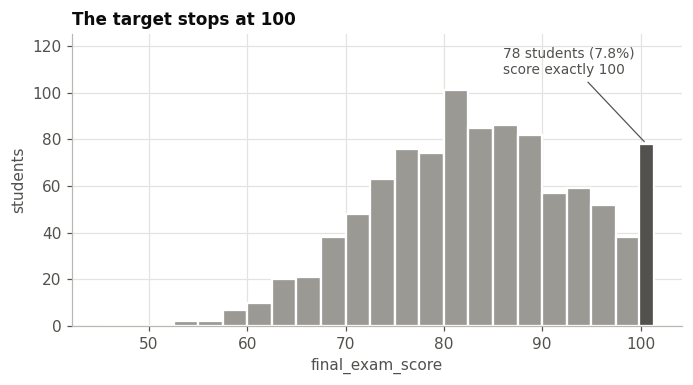

In [5]:
y_all = raw[TARGET]
at_cap = (y_all >= 100).mean()
print(f"mean {y_all.mean():.2f}, SD {y_all.std():.2f}, min {y_all.min():.1f}, max {y_all.max():.1f}")
print(f"share of students at the ceiling (score = 100): {at_cap:.1%} ({int((y_all >= 100).sum())} students)")

fig, ax = plt.subplots(figsize=(6.4, 3.6))
below = y_all[y_all < 100]
ax.hist(below, bins=np.arange(45, 100.1, 2.5), color=NEUTRAL, edgecolor="white", linewidth=1.5)
n_cap = int((y_all >= 100).sum())
ax.bar(100.6, n_cap, width=1.6, color=INK2, edgecolor="white", linewidth=1.5)
ax.set_ylim(0, 125)
ax.annotate(f"{n_cap} students ({at_cap:.1%})\nscore exactly 100", xy=(100.6, n_cap), xytext=(86, 108),
            color=INK2, fontsize=9, arrowprops=dict(arrowstyle="-", color=INK2, linewidth=0.8))
ax.set_xlabel("final_exam_score")
ax.set_ylabel("students")
ax.set_title("The target stops at 100", loc="left")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig1_target_distribution.png")
plt.show()

## 2. Preprocessing and feature engineering

Cleaning outcome: no missing values, no duplicate rows and no impossible values, so no row is removed. I drop `student_id` and `final_grade`.

Two feature sets are compared:

- **Scenario A (group protocol):** the six behavioural predictors used in Stage 1: study hours, attendance, sleep hours, internet access, extracurricular activities, part-time job.
- **Scenario B (extension):** scenario A plus `previous_grade`. Ngoc An's dataset is run with and without prior grades (G1, G2). Scenario B gives the group the same contrast for my dataset.

Encoding and scaling live inside the `Pipeline`, so they are fitted on training folds only.

In [6]:
df = raw.drop(columns=["student_id", "final_grade", "gender", "parental_education"])

NUM_A = ["study_time_hours", "attendance_percent", "sleep_hours"]
CAT_A = ["internet_access", "extracurricular_activities", "part_time_job"]
NUM_B = NUM_A + ["previous_grade"]
CAT_B = CAT_A

Y_SD = df[TARGET].std()          # SD of the target, used to normalise RMSE
print(f"records {len(df)}, target SD {Y_SD:.3f}")


def make_preprocessor(num_cols, cat_cols, scale):
    # Scale numeric columns only when the model needs it (Linear Regression).
    numeric_step = StandardScaler() if scale else "passthrough"
    return ColumnTransformer([
        ("num", numeric_step, num_cols),
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), cat_cols),
    ])


def make_pipeline(name, num_cols, cat_cols):
    estimators = {
        "Linear Regression": LinearRegression(),
        "Decision Tree": DecisionTreeRegressor(random_state=SEED),
        "Random Forest": RandomForestRegressor(random_state=SEED),
    }
    prep = make_preprocessor(num_cols, cat_cols, scale=(name == "Linear Regression"))
    return Pipeline([("prep", prep), ("model", estimators[name])])


def regression_metrics(y_true, y_pred):
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    return {
        "r2": float(r2_score(y_true, y_pred)),
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "rmse": float(rmse),
        "nrmse": float(rmse / Y_SD),
    }


def run_protocol(data, num_cols, cat_cols, label, evaluate_test=True):
    # The group protocol in one function. Returns (results table, fitted searches, split, predictions).
    X, y = data[num_cols + cat_cols], data[TARGET]
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=TEST_SIZE, random_state=SEED)
    cv = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

    rows, fitted, preds = [], {}, {}
    for name in MODELS:
        search = GridSearchCV(make_pipeline(name, num_cols, cat_cols), GRIDS[name],
                              cv=cv, scoring="r2", refit=True, n_jobs=-1)
        search.fit(X_tr, y_tr)
        best = search.best_index_
        folds = np.array([search.cv_results_[f"split{k}_test_score"][best] for k in range(N_FOLDS)])

        row = {
            "setting": label, "model": name,
            "best_params": {k.replace("model__", ""): v for k, v in search.best_params_.items()},
            "cv_r2_mean": folds.mean(), "cv_r2_sd": folds.std(ddof=1), "cv_folds": folds.round(4).tolist(),
        }
        if evaluate_test:
            pred = search.predict(X_te)
            row.update({f"test_{k}": v for k, v in regression_metrics(y_te, pred).items()})
            row["train_r2"] = r2_score(y_tr, search.predict(X_tr))
            preds[name] = pred
        rows.append(row)
        fitted[name] = search
    return pd.DataFrame(rows), fitted, (X_tr, X_te, y_tr, y_te), preds


def show(res):
    t = res.copy()
    t["CV R2 (mean +/- SD)"] = [f"{m:.3f} +/- {s:.3f}" for m, s in zip(t.cv_r2_mean, t.cv_r2_sd)]
    cols = ["model", "best_params", "CV R2 (mean +/- SD)", "test_r2", "test_mae", "test_rmse", "test_nrmse", "train_r2"]
    return t[cols].round(3).set_index("model")

records 1000, target SD 10.341


### Feature engineering check

Two features could help a model that sees only raw columns:

- `effective_study` = study hours x attendance / 100. A student who studies many hours but skips class may gain less.
- `sleep_gap` = |sleep hours - 7|. Both very short and very long sleep may hurt, which a straight line cannot express. I use 7 hours because it is close to the sample median (6.8 h).

Rule set before looking at any test score: keep the new features only if the cross-validated R² on the training set rises by more than one SD of the fold scores for that model. Only cross-validation numbers are shown here.

In [7]:
df_fe = df.copy()
df_fe["effective_study"] = df_fe["study_time_hours"] * df_fe["attendance_percent"] / 100
df_fe["sleep_gap"] = (df_fe["sleep_hours"] - 7).abs()

base_cv = run_protocol(df_fe, NUM_A, CAT_A, "raw features", evaluate_test=False)[0]
fe_cv = run_protocol(df_fe, NUM_A + ["effective_study", "sleep_gap"], CAT_A, "with engineered", evaluate_test=False)[0]

fe_check = pd.DataFrame({
    "model": base_cv.model,
    "CV R2 raw": base_cv.cv_r2_mean,
    "CV R2 with FE": fe_cv.cv_r2_mean,
    "gain": fe_cv.cv_r2_mean - base_cv.cv_r2_mean,
    "larger fold SD": np.maximum(base_cv.cv_r2_sd, fe_cv.cv_r2_sd),
})
fe_check["keep?"] = fe_check["gain"] > fe_check["larger fold SD"]
fe_check.round(3).set_index("model")

,CV R2 raw,CV R2 with FE,gain,larger fold SD,keep?
model,,,,,
Linear Regression,0.480,0.477,-0.003,0.034,False
Decision Tree,0.328,0.346,0.018,0.080,False
Random Forest,0.443,0.449,0.006,0.025,False


No model passes the rule, so the final models use the raw features. The engineered columns add parameters without a reliable gain.

## 3. Application of the three models and parameter tuning

### 3.1 Reference point

A model that always predicts the training mean shows what R² = 0 looks like on this split.

In [8]:
X_a = df[NUM_A + CAT_A]
Xtr0, Xte0, ytr0, yte0 = train_test_split(X_a, df[TARGET], test_size=TEST_SIZE, random_state=SEED)
dummy = DummyRegressor(strategy="mean").fit(Xtr0, ytr0)
dm = regression_metrics(yte0, dummy.predict(Xte0))
print({k: round(v, 3) for k, v in dm.items()})
print(f"train {len(Xtr0)} rows, test {len(Xte0)} rows")

{'r2': -0.025, 'mae': 8.585, 'rmse': 10.501, 'nrmse': 1.015}
train 800 rows, test 200 rows


### 3.2 Scenario A: behavioural predictors (group protocol)

Linear Regression is fitted directly. Decision Tree (15 combinations) and Random Forest (12 combinations) are tuned with 5-fold cross-validation on the training set.

In [9]:
res_a, fit_a, split_a, pred_a = run_protocol(df, NUM_A, CAT_A, "A: behaviour only")
show(res_a)

,best_params,CV R2 (mean +/- SD),test_r2,test_mae,test_rmse,test_nrmse,train_r2
model,,,,,,,
Linear Regression,{},0.480 +/- 0.032,0.386,6.575,8.128,0.786,0.494
Decision Tree,"{'max_depth': 5, 'min_samples_leaf': 10}",0.328 +/- 0.080,0.269,7.231,8.872,0.858,0.496
Random Forest,"{'max_depth': 10, 'max_features': 'sqrt', 'n_estimators': 300}",0.443 +/- 0.025,0.338,6.803,8.440,0.816,0.841


### 3.3 Scenario B: behavioural predictors plus `previous_grade`

In [10]:
res_b, fit_b, split_b, pred_b = run_protocol(df, NUM_B, CAT_B, "B: behaviour + previous grade")
show(res_b)

,best_params,CV R2 (mean +/- SD),test_r2,test_mae,test_rmse,test_nrmse,train_r2
model,,,,,,,
Linear Regression,{},0.659 +/- 0.047,0.619,4.965,6.402,0.619,0.673
Decision Tree,"{'max_depth': None, 'min_samples_leaf': 10}",0.446 +/- 0.065,0.492,5.748,7.393,0.715,0.688
Random Forest,"{'max_depth': 10, 'max_features': 0.5, 'n_estimators': 300}",0.594 +/- 0.055,0.585,5.243,6.683,0.646,0.900


Fold-level scores of the tuned models (used for the tie rule and shared with the group):

In [11]:
def folds_table(res):
    t = pd.DataFrame(res.cv_folds.tolist(), index=res.model, columns=[f"fold {i + 1}" for i in range(N_FOLDS)])
    return t.round(3)

print("Scenario A"); display(folds_table(res_a))
print("Scenario B"); display(folds_table(res_b))

Scenario A


,fold 1,fold 2,fold 3,fold 4,fold 5
model,,,,,
Linear Regression,0.482,0.509,0.497,0.488,0.426
Decision Tree,0.348,0.420,0.366,0.298,0.208
Random Forest,0.439,0.470,0.467,0.426,0.414


Scenario B


,fold 1,fold 2,fold 3,fold 4,fold 5
model,,,,,
Linear Regression,0.657,0.620,0.717,0.695,0.607
Decision Tree,0.454,0.401,0.524,0.488,0.361
Random Forest,0.598,0.563,0.669,0.618,0.523


## 4. Results and comparison

### 4.1 Summary tables

In [12]:
summary = pd.concat([res_a, res_b], ignore_index=True)
summary_view = summary[["setting", "model", "cv_r2_mean", "cv_r2_sd", "test_r2", "test_mae", "test_rmse", "test_nrmse"]].round(3)
summary_view

,setting,model,cv_r2_mean,cv_r2_sd,test_r2,test_mae,test_rmse,test_nrmse
0,A: behaviour only,Linear Regression,0.480,0.032,0.386,6.575,8.128,0.786
1,A: behaviour only,Decision Tree,0.328,0.080,0.269,7.231,8.872,0.858
2,A: behaviour only,Random Forest,0.443,0.025,0.338,6.803,8.440,0.816
3,B: behaviour + previous grade,Linear Regression,0.659,0.047,0.619,4.965,6.402,0.619
4,B: behaviour + previous grade,Decision Tree,0.446,0.065,0.492,5.748,7.393,0.715
5,B: behaviour + previous grade,Random Forest,0.594,0.055,0.585,5.243,6.683,0.646


### 4.2 Which differences are real? (tie rule)

The group rule: a gap in cross-validated R² smaller than one SD counts as a tie.

In [13]:
def tie_table(res, label):
    folds = {r.model: np.array(r.cv_folds) for r in res.itertuples()}
    out = []
    for a, b in [("Linear Regression", "Random Forest"), ("Linear Regression", "Decision Tree"), ("Random Forest", "Decision Tree")]:
        diff = (folds[a] - folds[b]).mean()
        sd = max(folds[a].std(ddof=1), folds[b].std(ddof=1))
        verdict = "tie" if abs(diff) < sd else (f"{a} higher" if diff > 0 else f"{b} higher")
        out.append({"setting": label, "comparison": f"{a} - {b}", "CV R2 difference": diff, "larger SD": sd, "verdict": verdict})
    return pd.DataFrame(out)

ties = pd.concat([tie_table(res_a, "A"), tie_table(res_b, "B")], ignore_index=True)
ties.round(3)

,setting,comparison,CV R2 difference,larger SD,verdict
0,A,Linear Regression - Random Forest,0.037,0.032,Linear Regression higher
1,A,Linear Regression - Decision Tree,0.153,0.080,Linear Regression higher
2,A,Random Forest - Decision Tree,0.116,0.080,Random Forest higher
3,B,Linear Regression - Random Forest,0.065,0.055,Linear Regression higher
4,B,Linear Regression - Decision Tree,0.213,0.066,Linear Regression higher
5,B,Random Forest - Decision Tree,0.149,0.066,Random Forest higher


### 4.3 Figure: test and cross-validated R²

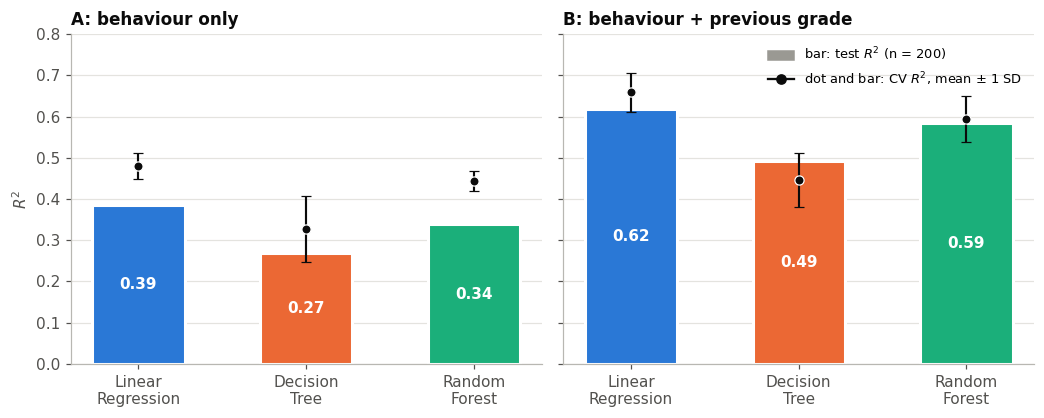

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.9), sharey=True)
for ax, res, title in [(axes[0], res_a, "A: behaviour only"), (axes[1], res_b, "B: behaviour + previous grade")]:
    xs = np.arange(len(res))
    ax.bar(xs, res.test_r2, width=0.55, color=[COLORS[m] for m in res.model], edgecolor="white", linewidth=2)
    ax.errorbar(xs, res.cv_r2_mean, yerr=res.cv_r2_sd, fmt="o", color=INK, ecolor=INK, elinewidth=1.4,
                capsize=3, markersize=6, markeredgecolor="white", markeredgewidth=0.8, zorder=5)
    for x, v in zip(xs, res.test_r2):
        ax.text(x, v / 2, f"{v:.2f}", ha="center", va="center", color="white", fontsize=10, fontweight="bold")
    ax.set_xticks(xs)
    ax.set_xticklabels([m.replace(" ", "\n") for m in res.model])
    ax.set_title(title, loc="left")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("$R^2$")
axes[0].set_ylim(0, 0.8)
handles = [plt.Rectangle((0, 0), 1, 1, color=NEUTRAL), plt.Line2D([], [], marker="o", color=INK, linestyle="-", markersize=6)]
axes[1].legend(handles, ["bar: test $R^2$ (n = 200)", "dot and bar: CV $R^2$, mean $\pm$ 1 SD"], loc="upper right", frameon=False, fontsize=8.5)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig2_r2_by_model.png")
plt.show()

### 4.4 Figure: predicted against actual scores

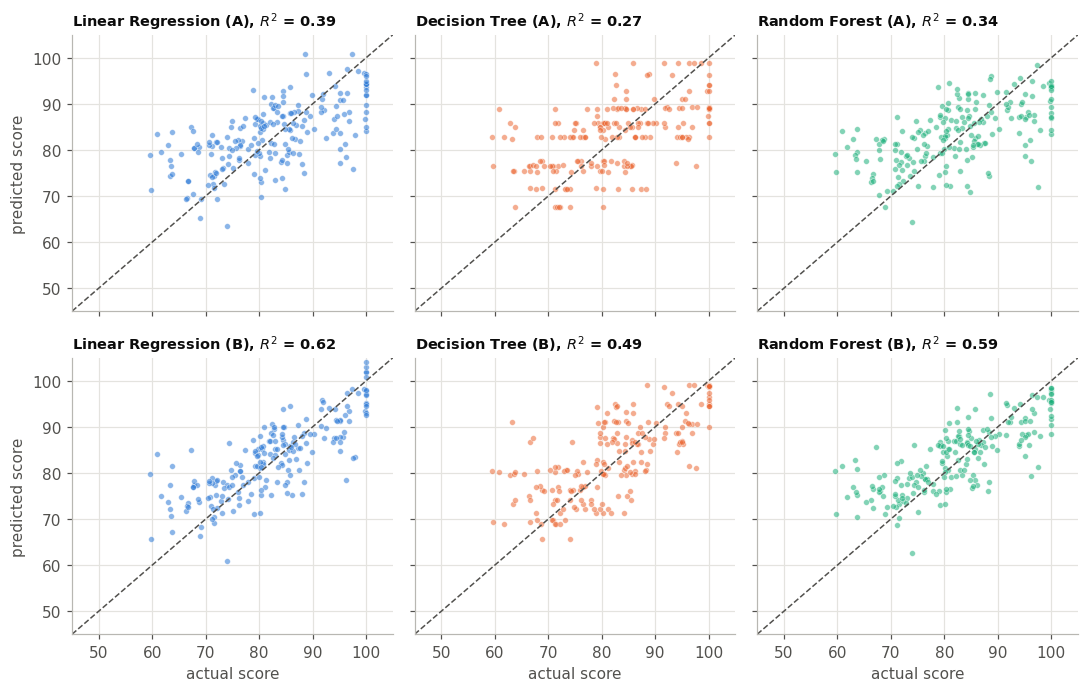

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(10, 6.4), sharex=True, sharey=True)
for r, (preds, res, split, tag) in enumerate([(pred_a, res_a, split_a, "A"), (pred_b, res_b, split_b, "B")]):
    y_te = split[3]
    for c, name in enumerate(MODELS):
        ax = axes[r, c]
        ax.scatter(y_te, preds[name], s=14, alpha=0.55, color=COLORS[name], edgecolor="white", linewidth=0.4)
        ax.plot([45, 105], [45, 105], color=INK2, linewidth=1, linestyle="--")
        r2 = res.loc[res.model == name, "test_r2"].iloc[0]
        ax.set_title(f"{name} ({tag}), $R^2$ = {r2:.2f}", fontsize=9.5, loc="left")
        if r == 1:
            ax.set_xlabel("actual score")
        if c == 0:
            ax.set_ylabel("predicted score")
ax.set_xlim(45, 105); ax.set_ylim(45, 105)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig3_pred_vs_actual.png")
plt.show()

### 4.5 Ceiling check

Because scores stop at 100, a prediction above 100 is impossible. I count how many predictions exceed 100 and whether capping them changes the test R².

In [16]:
rows = []
for tag, preds, split in [("A", pred_a, split_a), ("B", pred_b, split_b)]:
    y_te = split[3]
    for name in MODELS:
        p = preds[name]
        rows.append({"scenario": tag, "model": name, "predictions > 100": int((p > 100).sum()),
                     "R2 as predicted": r2_score(y_te, p), "R2 capped at 100": r2_score(y_te, np.minimum(p, 100))})
pd.DataFrame(rows).round(4)

,scenario,model,predictions > 100,R2 as predicted,R2 capped at 100
0,A,Linear Regression,2,0.3863,0.3874
1,A,Decision Tree,0,0.2687,0.2687
2,A,Random Forest,0,0.3382,0.3382
3,B,Linear Regression,6,0.6192,0.6288
4,B,Decision Tree,0,0.4922,0.4922
5,B,Random Forest,0,0.5850,0.5850


### 4.6 What drives the predictions

Linear Regression coefficients: numeric features are standardised, so a coefficient is the change in score for +1 SD. Binary features show the change from No to Yes.

In [17]:
def lr_coefficients(fitted_lr):
    pipe = fitted_lr.best_estimator_
    names = [n.split("__", 1)[1] for n in pipe.named_steps["prep"].get_feature_names_out()]
    return pd.Series(pipe.named_steps["model"].coef_, index=names)

coefs = pd.concat({"A": lr_coefficients(fit_a["Linear Regression"]),
                   "B": lr_coefficients(fit_b["Linear Regression"])}, axis=1).round(2)
coefs

,A,B
study_time_hours,5.85,6.04
attendance_percent,3.13,3.15
sleep_hours,1.23,1.21
internet_access_Yes,5.74,6.02
extracurricular_activities_Yes,0.39,0.80
part_time_job_Yes,-4.00,-3.55
previous_grade,NaN,4.36


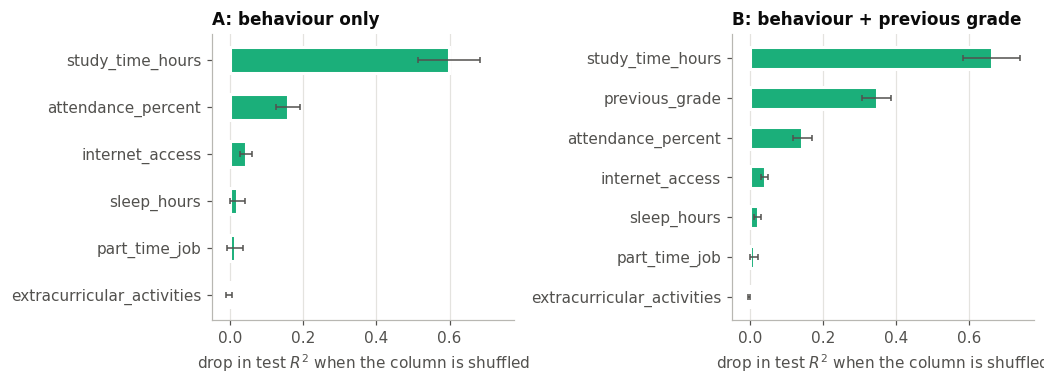

,A: behaviour only,B: behaviour + previous grade
attendance_percent,0.159,0.144
extracurricular_activities,-0.003,-0.002
internet_access,0.043,0.040
part_time_job,0.013,0.010
previous_grade,NaN,0.347
sleep_hours,0.020,0.022
study_time_hours,0.597,0.661


In [18]:
imp_tables = {}
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.6), sharex=True)
for ax, fitted, split, title in [(axes[0], fit_a, split_a, "A: behaviour only"), (axes[1], fit_b, split_b, "B: behaviour + previous grade")]:
    X_te, y_te = split[1], split[3]
    pi = permutation_importance(fitted["Random Forest"].best_estimator_, X_te, y_te,
                                n_repeats=30, random_state=SEED, scoring="r2")
    imp = pd.Series(pi.importances_mean, index=X_te.columns).sort_values()
    err = pd.Series(pi.importances_std, index=X_te.columns)[imp.index]
    imp_tables[title] = imp.sort_values(ascending=False)
    ax.barh(imp.index, imp.values, xerr=err.values, height=0.55, color=COLORS["Random Forest"],
            edgecolor="white", linewidth=2, error_kw=dict(ecolor=INK2, elinewidth=1, capsize=2))
    ax.set_title(title, loc="left")
    ax.set_xlabel("drop in test $R^2$ when the column is shuffled")
    ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig4_rf_permutation_importance.png")
plt.show()
pd.DataFrame(imp_tables).round(3)

In [19]:
# top of the tuned Decision Tree for scenario B (first three levels)
tree_pipe = fit_b["Decision Tree"].best_estimator_
tree_names = [n.split("__", 1)[1] for n in tree_pipe.named_steps["prep"].get_feature_names_out()]
print(export_text(tree_pipe.named_steps["model"], feature_names=tree_names, max_depth=2))

|--- study_time_hours <= 3.95
|   |--- previous_grade <= 74.65
|   |   |--- attendance_percent <= 84.95
|   |   |   |--- truncated branch of depth 6
|   |   |--- attendance_percent >  84.95
|   |   |   |--- truncated branch of depth 6
|   |--- previous_grade >  74.65
|   |   |--- study_time_hours <= 1.55
|   |   |   |--- truncated branch of depth 2
|   |   |--- study_time_hours >  1.55
|   |   |   |--- truncated branch of depth 7
|--- study_time_hours >  3.95
|   |--- previous_grade <= 57.15
|   |   |--- attendance_percent <= 85.25
|   |   |   |--- truncated branch of depth 3
|   |   |--- attendance_percent >  85.25
|   |   |   |--- value: [87.29]
|   |--- previous_grade >  57.15
|   |   |--- study_time_hours <= 5.55
|   |   |   |--- truncated branch of depth 7
|   |   |--- study_time_hours >  5.55
|   |   |   |--- truncated branch of depth 4



### 4.7 Stability of the single test split

The test set has 200 students, so one split can be lucky or unlucky. I repeat the 80/20 split with 20 different seeds, refit each model with its tuned parameters, and look at the spread of test R².

In [20]:
def split_stability(data, num_cols, cat_cols, fitted, seeds=range(20)):
    X, y = data[num_cols + cat_cols], data[TARGET]
    rows = []
    for seed in seeds:
        X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=TEST_SIZE, random_state=seed)
        for name in MODELS:
            pipe = make_pipeline(name, num_cols, cat_cols).set_params(**fitted[name].best_params_)
            pipe.fit(X_tr, y_tr)
            rows.append({"seed": seed, "model": name, "r2": r2_score(y_te, pipe.predict(X_te))})
    return pd.DataFrame(rows)

stab_a = split_stability(df, NUM_A, CAT_A, fit_a)
stab_b = split_stability(df, NUM_B, CAT_B, fit_b)

def stab_summary(stab, tag):
    g = stab.groupby("model").r2
    t = pd.DataFrame({"mean": g.mean(), "SD": g.std(), "min": g.min(), "max": g.max()})
    wide = stab.pivot(index="seed", columns="model", values="r2")
    t["best model in x of 20 splits"] = [int((wide.idxmax(axis=1) == m).sum()) for m in t.index]
    t.insert(0, "scenario", tag)
    return t.loc[MODELS]

pd.concat([stab_summary(stab_a, "A"), stab_summary(stab_b, "B")]).round(3)

,scenario,mean,SD,min,max,best model in x of 20 splits
model,,,,,,
Linear Regression,A,0.462,0.046,0.363,0.558,19
Decision Tree,A,0.321,0.055,0.227,0.440,0
Random Forest,A,0.429,0.038,0.363,0.500,1
Linear Regression,B,0.654,0.034,0.599,0.718,20
Decision Tree,B,0.429,0.060,0.327,0.518,0
Random Forest,B,0.599,0.038,0.541,0.679,0


## 5. Export for the group comparison (Section 5 of the report)

In [21]:
export = summary.copy()
export.insert(0, "student", "Quang Trung Nguyen")
export["n_records"] = len(df)
export["n_train"] = len(split_a[0])
export["n_test"] = len(split_a[1])
for k in range(N_FOLDS):
    export[f"cv_fold_{k + 1}"] = export["cv_folds"].apply(lambda f, k=k: f[k])
export["best_params"] = export["best_params"].astype(str)
export = export.drop(columns=["cv_folds"])
export.round(4).to_csv("results_QuangTrung.csv", index=False)
export.round(3)[["student", "setting", "model", "test_r2", "test_mae", "test_rmse", "test_nrmse", "cv_r2_mean", "cv_r2_sd"]]

,student,setting,model,test_r2,test_mae,test_rmse,test_nrmse,cv_r2_mean,cv_r2_sd
0,Quang Trung Nguyen,A: behaviour only,Linear Regression,0.386,6.575,8.128,0.786,0.480,0.032
1,Quang Trung Nguyen,A: behaviour only,Decision Tree,0.269,7.231,8.872,0.858,0.328,0.080
2,Quang Trung Nguyen,A: behaviour only,Random Forest,0.338,6.803,8.440,0.816,0.443,0.025
3,Quang Trung Nguyen,B: behaviour + previous grade,Linear Regression,0.619,4.965,6.402,0.619,0.659,0.047
4,Quang Trung Nguyen,B: behaviour + previous grade,Decision Tree,0.492,5.748,7.393,0.715,0.446,0.065
5,Quang Trung Nguyen,B: behaviour + previous grade,Random Forest,0.585,5.243,6.683,0.646,0.594,0.055


## 6. Conclusion for my dataset

**Best model: Linear Regression in both scenarios.**

| Scenario | Linear Regression | Random Forest | Decision Tree |
| --- | --- | --- | --- |
| A: behaviour only, test R² (CV mean ± SD) | 0.386 (0.480 ± 0.032) | 0.338 (0.443 ± 0.025) | 0.269 (0.328 ± 0.080) |
| B: with previous grade, test R² (CV mean ± SD) | 0.619 (0.659 ± 0.047) | 0.580 (0.594 ± 0.056) | 0.492 (0.446 ± 0.065) |

- Linear Regression is first in the cross-validated R² and the test R² in both scenarios. Over 20 random splits it has the highest test R² in 18 splits (A) and 20 splits (B).
- Its lead over Random Forest is small: 0.037 (A) and 0.065 (B) in cross-validated R², just above one SD, so I call it a modest lead. Its lead over the Decision Tree (0.153 and 0.213) is clear.
- Random Forest fits the training data much more closely (train R² 0.84 in A) than the test data (0.34), so extra flexibility does not pay off on 800 training rows with noisy behavioural predictors.
- Study hours dominate every model. Adding `previous_grade` raises the best test R² from 0.386 to 0.619.
- Limits: the test set has 200 students, and the test R² varies by about 0.04 to 0.06 (SD) across splits. The target is capped at 100. The results describe association, not cause.